# Model comparison — all models

This notebook reads every `models/<name>/metrics.json`, written by the notebooks or by `models/_template_train.py`. It builds the consolidated comparison table and the comparison plots the report requires. Run it after all five models have been trained and committed. It works with however many models exist so far.

Outputs go to `results/model_comparison/`.

In [1]:
import os, sys, json, time
from pathlib import Path
# find the repo root (the folder that contains config.yaml) and make `pathsnap` importable
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook from inside the pathsnap-ml-hackathon repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap.dataset import FEATURES
from pathsnap import modeling as M
print("repo root:", ROOT)

repo root: C:\3rd year material\ML\Hackathon\pathsnap_preprocessing


In [2]:
OUT = ROOT / "results" / "model_comparison"
OUT.mkdir(parents=True, exist_ok=True)
runs = {}
for p in sorted((ROOT / "models").glob("*/metrics.json")):
    if p.parent.name.startswith("_"):
        continue
    runs[p.parent.name] = json.loads(p.read_text())
print("models found:", list(runs))

models found: ['mlp', 'random_forest']


## Consolidated comparison table

In [3]:
FAMILY = {"logistic_regression": "Linear / probabilistic", "knn": "Instance-based",
          "random_forest": "Ensemble (bagging)", "lightgbm": "Boosting", "mlp": "Neural network"}
rows = []
for name, r in runs.items():
    t = r["student_test"]
    rows.append({
        "Model": name,
        "Algorithm family": r.get("algorithm_family", FAMILY.get(name, "")),
        "Key configuration": r.get("config"),
        "Train rows/fold": r.get("train_rows_per_fold"),
        "CV macro F1": r["cv_f1_macro_mean"], "CV macro F1 std": r["cv_f1_macro_std"],
        "CV Top-1": r["cv_top1_mean"], "CV Top-1 std": r["cv_top1_std"],
        "Train Top-1": r.get("cv_train_top1_mean"),
        "Student-test Top-1": t["top1_accuracy"],
        "Student-test macro F1": t["f1_macro"],
        "Precision (macro)": t["precision_macro"], "Recall (macro)": t["recall_macro"],
        "Log loss": t["log_loss"],
        "Route continuity 1-hop": t.get("route_continuity_1hop"),
        "Route continuity 2-hop": t.get("route_continuity_2hop"),
        "Candidate miss rate": t["candidate_miss_rate"],
        "Train time (s)": r["train_seconds"],
        "Inference (ms / 1k rows)": r["inference_ms_per_1000_rows"],
    })
table = pd.DataFrame(rows).sort_values("Student-test Top-1", ascending=False).reset_index(drop=True)
table.to_csv(OUT / "model_comparison.csv", index=False)
table.drop(columns=["Key configuration"]).round(4)

,Model,Algorithm family,Train rows/fold,CV macro F1,CV macro F1 std,CV Top-1,CV Top-1 std,Train Top-1,Student-test Top-1,Student-test macro F1,Precision (macro),Recall (macro),Log loss,Route continuity 1-hop,Route continuity 2-hop,Candidate miss rate,Train time (s),Inference (ms / 1k rows)
0,random_forest,Ensemble (bagging),60000,0.9289,0.0180,0.8802,0.0321,0.9085,0.8885,0.9351,0.9450,0.9259,0.0629,0.7701,0.8701,0.0003,25.4799,2.7037
1,mlp,Neural network,80000,0.9293,0.0195,0.8833,0.0342,0.9027,0.8841,0.9300,0.9336,0.9265,0.0656,0.8032,0.8944,0.0003,25.0440,1.0217


## Comparison plots

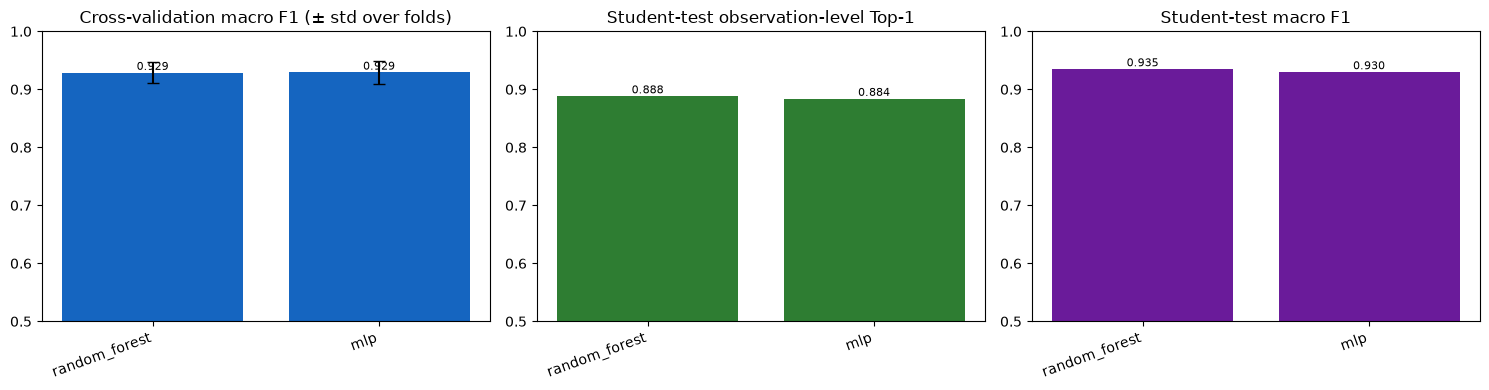

In [4]:
def bar(ax, col, err=None, title="", ylim=None, color="#1565c0"):
    x = np.arange(len(table))
    ax.bar(x, table[col], yerr=table[err] if err else None, capsize=4, color=color)
    ax.set_xticks(x, table["Model"], rotation=20, ha="right")
    ax.set_title(title)
    if ylim: ax.set_ylim(*ylim)
    for i, v in enumerate(table[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bar(ax[0], "CV macro F1", "CV macro F1 std", "Cross-validation macro F1 (± std over folds)", (0.5, 1))
bar(ax[1], "Student-test Top-1", None, "Student-test observation-level Top-1", (0.5, 1), "#2e7d32")
bar(ax[2], "Student-test macro F1", None, "Student-test macro F1", (0.5, 1), "#6a1b9a")
plt.tight_layout(); plt.savefig(OUT / "metric_comparison.png", dpi=130); plt.show()

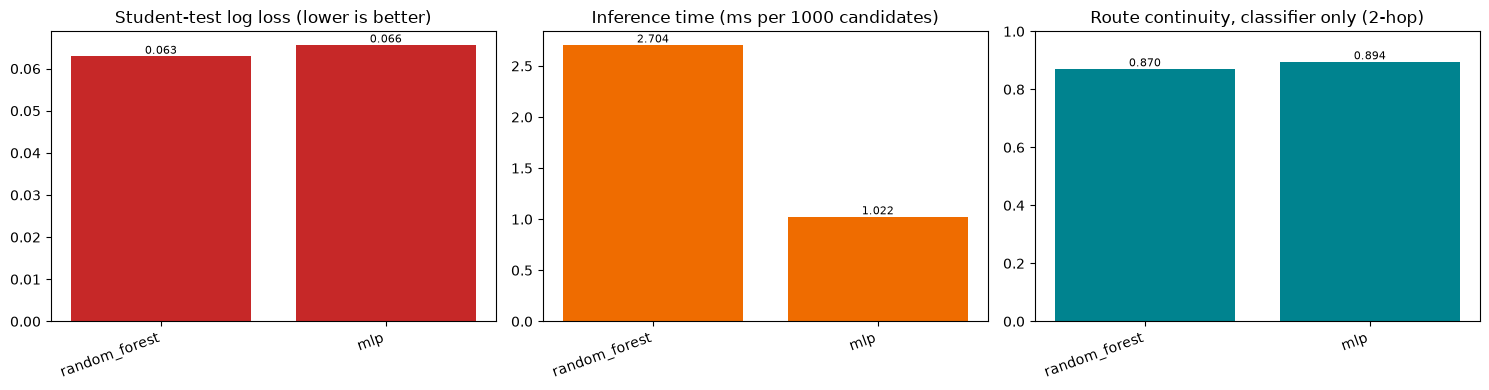

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bar(ax[0], "Log loss", None, "Student-test log loss (lower is better)", None, "#c62828")
bar(ax[1], "Inference (ms / 1k rows)", None, "Inference time (ms per 1000 candidates)", None, "#ef6c00")
if table["Route continuity 1-hop"].notna().any():
    bar(ax[2], "Route continuity 2-hop", None, "Route continuity, classifier only (2-hop)", (0, 1), "#00838f")
plt.tight_layout(); plt.savefig(OUT / "logloss_time_continuity.png", dpi=130); plt.show()

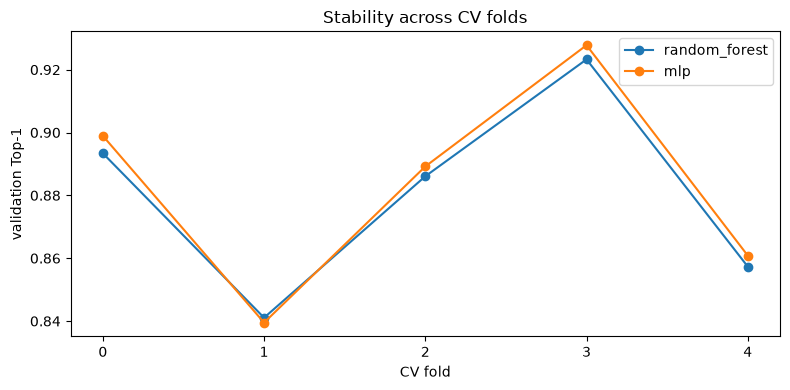

In [6]:
# CV stability: per-fold Top-1 for each model
fig, ax = plt.subplots(figsize=(8, 4))
for name in table["Model"]:
    f = ROOT / "models" / name / "cv_folds.csv"
    if f.exists():
        c = pd.read_csv(f)
        ax.plot(c["fold"], c["top1_accuracy"], "o-", label=name)
ax.set(xlabel="CV fold", ylabel="validation Top-1", title="Stability across CV folds")
ax.set_xticks(range(5)); ax.legend(); plt.tight_layout()
plt.savefig(OUT / "cv_fold_stability.png", dpi=130); plt.show()

## Confusion matrices (student-test, threshold 0.5)

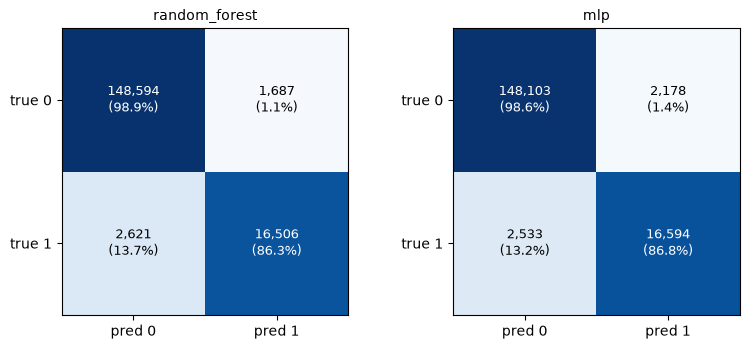

In [7]:
n = len(table)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.6))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, table["Model"]):
    M.plot_confusion(runs[name]["student_test"]["confusion_matrix"], name, ax=ax)
plt.tight_layout(); plt.savefig(OUT / "confusion_matrices.png", dpi=130); plt.show()

## Model selection
Choose the primary selection metric and state it in the report. A suggestion: **student-test Top-1**, together with **CV Top-1 stability** and **log loss**. The HMM uses the classifier's probabilities as emissions, so probability quality matters, not just ranking. Then weigh inference time and model size, because the model runs live in the API.

The cell below only ranks the models; the decision and its justification are yours to write.

In [8]:
table[["Model", "CV Top-1", "CV Top-1 std", "Student-test Top-1", "Student-test macro F1",
       "Log loss", "Inference (ms / 1k rows)"]].sort_values("Student-test Top-1", ascending=False).round(4)

,Model,CV Top-1,CV Top-1 std,Student-test Top-1,Student-test macro F1,Log loss,Inference (ms / 1k rows)
0,random_forest,0.8802,0.0321,0.8885,0.9351,0.0629,2.7037
1,mlp,0.8833,0.0342,0.8841,0.9300,0.0656,1.0217
